# Ajustes NOGSE libres en función de $x$ (barridos AUTOX, lóbulos trapezoidales)

Versión en $x$ de `nogse_fits_trapezoidal_lobes.ipynb`. Los archivos `nogse_v2003_fov220_m128_sl01_R1_autox` (secuencia v2.00.3) tienen, para cada $G$ fijo (10, 20 y 30 mT/m), una serie con 2 b0 y, para cada $x$ del barrido (de $x=0$, Hahn puro, a $x=T/N$, CPMG), las tres direcciones del escáner. Este notebook lee `master.long.parquet`, ajusta solo $D_0$ (con $M_0=1$) a cada curva $M(x)$ y a su contraste respecto del límite Hahn, y guarda figuras y tablas en `signal_analysis/results/autox/sub-<SUB>/ses-<SESSION_ID>/`.

La versión con el piso de ruido de la magnitud restado es `nogse_fits_autox_noise_floor.ipynb`.

## Qué datos entran y de dónde sale cada parámetro

Cada fila de `master.long.parquet` es la señal de un volumen en un ROI. Se usan las filas del barrido en $x$ (`type = AUTOX`, o un protocolo `<D>dir<X>x`) del sujeto y la sesión elegidos, `stat = avg`, sin los dos b0.

| Columna | Símbolo | Qué es | De dónde viene |
|---|---|---|---|
| `value` | $S(x)$ | media de la señal en el ROI (máscara manual) del volumen | `signal_extraction` sobre el NIfTI (`raw` o `den_gr`) |
| `S0`, `value_norm` | $S_0$, $M=S/S_0$ | $S_0$ es la media de los dos b0 de la **misma** serie (mismo $G$) | ingest de `signal_analysis` |
| `TN` | $T$ | duración del bloque NOGSE, 50 ms; también `td_ms` | `sequence_parameters_phantoms.xlsx` |
| `N` | $N$ | número de períodos, 2 | ídem |
| `G` | $G$ | amplitud **fija** de la serie: 10, 20 o 30 mT/m (una serie por $G$) | ídem |
| `ramp_time_ms` | $t_r$ | rampa de cada trapecio, 0.32 ms | ídem |
| `bvalue` | $b$ | b-value exacto del `.bval` | `.bval` de BIDS |
| `x` | $x$ | período CPMG de **cada volumen** (ms): de $0$ (Hahn puro) a $T/N$ (CPMG) en 20 pasos | ingest (`add_x_sweep_derivatives`): invierte $b/G^2 = k_{trap}(T,N,x,t_r)$ |
| `y` | $y$ | período Hahn, $y=T-(N-1)x$ | ídem |
| `direction` | — | eje del gradiente: 1 = $x$, 2 = $y$, 3 = $z$ | `.bvec` |

Los $x$ jugables son $0$ y $[4t_r,\ T/N]$ (cada medio lóbulo contiene dos rampas): entre $0$ y $4t_r = 1.28$ ms no hay forma de onda posible, por eso las curvas del modelo se dibujan en $[4t_r, T/N]$ y el valor en $x=0$ como un rombo abierto.

**Advertencia.** Este notebook ajusta las señales medidas, con el piso de ruido incluido. Con $S/S_0 \lesssim 0.2$, o con $S_0$ cerca del piso (en PHANTOM-3, `fiber2` tiene $S_0\approx21$ y el piso es $\approx17$ unidades del escáner), la señal no baja como predice el modelo y el $D_0$ sale sesgado hacia abajo: usar entonces el notebook con piso.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.optimize import minimize_scalar


def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / 'Data-BIDS').is_dir() and (candidate / 'repos' / 'signal_analysis').is_dir():
            return candidate
    raise FileNotFoundError('No encuentro la raíz del proyecto.')


PROJECT_ROOT = find_project_root()
REPO_ROOT = PROJECT_ROOT / 'repos' / 'signal_analysis'
SRC_ROOT = REPO_ROOT / 'src'
if str(SRC_ROOT) not in sys.path:
    sys.path.insert(0, str(SRC_ROOT))

from data_processing.result_signals import X_SWEEP_NAME
from fitting.b_from_g import nogse_trapezoid_b_per_g2
from models.model_fitting import _GYRO

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 50)
PROJECT_ROOT

PosixPath('/mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE')

## Configuración

Por defecto se usa la rama denoised + Gibbs-removal (`den_gr--manual`); cambiar solo `ANALYSIS_TAG` repite el análisis con `raw--manual`. `SESSION_ID` es la sesión BIDS del barrido; `ROIS = None` usa todos los ROIs del barrido.

In [2]:
OUTPUT_NAME = 'autox'
ANALYSIS_TAG = 'den_gr--manual'  # alternativa: 'raw--manual'
SUB = 'PHANTOM-3'
SESSION_ID = '20261026NOGSEV2003FOV220M128SL01R1AUTOX'
ROIS = None  # p. ej. ['water1', 'water2']; None: todos los ROIs del barrido
STAT = 'avg'
D0_BOUNDS_MM2_S = (1e-4, 1e-2)
FIT_M0 = True  # False: M0 = 1 fixed, exactly as in the G notebooks

MASTER_PATH = (PROJECT_ROOT / 'Data-BIDS' / 'derivatives' / 'signal_analysis' /
               ANALYSIS_TAG / 'phantoms' / 'nogse_experiments' / 'master.long.parquet')
OUTPUT_ROOT = REPO_ROOT / 'results' / OUTPUT_NAME / f'sub-{SUB}' / f'ses-{SESSION_ID}'
SIGNAL_DIR = OUTPUT_ROOT / 'signals'
CONTRAST_DIR = OUTPUT_ROOT / 'contrasts'
SUMMARY_DIR = OUTPUT_ROOT / 'summary'
TABLE_DIR = OUTPUT_ROOT / 'tables'
for folder in (SIGNAL_DIR, CONTRAST_DIR, SUMMARY_DIR, TABLE_DIR):
    folder.mkdir(parents=True, exist_ok=True)

NUMERIC = ['td_ms', 'TN', 'N', 'x', 'y', 'G', 'g', 'ramp_time_ms', 'bvalue', 'b_step', 'value', 'S0', 'value_norm']
master = pd.read_parquet(MASTER_PATH)
is_sweep = (master['type'].astype(str).str.strip().str.upper().eq('AUTOX')
            | master['protocol'].astype(str).str.contains(X_SWEEP_NAME))
available = sorted(set(master.loc[is_sweep, ['subj', 'session_id']].astype(str).itertuples(index=False, name=None)))
data = master.loc[is_sweep & (master['subj'].astype(str) == SUB) &
                  (master['session_id'].astype(str) == SESSION_ID) &
                  (master['stat'].astype(str) == STAT)].copy()
if ROIS is not None:
    data = data.loc[data['roi'].astype(str).isin(ROIS)]
for column in NUMERIC:
    data[column] = pd.to_numeric(data[column], errors='coerce')
data = data.loc[data['b_step'] > 0].dropna(subset=NUMERIC)  # the b0 volumes have no x
if data.empty:
    raise ValueError(f'No hay barridos en x para SUB={SUB!r}, SESSION_ID={SESSION_ID!r}. Disponibles (subj, session_id): {available}')
data['roi'] = data['roi'].astype(str)
data['direction'] = data['direction'].astype(str)
if not np.allclose(data['TN'], data['td_ms']):
    raise ValueError('TN y td_ms no coinciden: revisar la tabla de parámetros.')
if not np.allclose(data['g'], data['G']):
    raise ValueError('En un barrido en x el g de cada volumen pesado debe ser el G de la serie.')

print('Sujeto:', SUB, '| sesión:', SESSION_ID, '| tag:', ANALYSIS_TAG)
print('Master:', MASTER_PATH)
print('Salida:', OUTPUT_ROOT)
display(data.groupby(['roi', 'G']).agg(
    n_points=('x', 'size'), n_x=('x', 'nunique'), x_min_ms=('x', 'min'), x_max_ms=('x', 'max'),
    TN_ms=('TN', 'first'), ramp_ms=('ramp_time_ms', 'first'), S0=('S0', 'first')).reset_index())

Sujeto: PHANTOM-3 | sesión: 20261026NOGSEV2003FOV220M128SL01R1AUTOX | tag: den_gr--manual
Master: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/Data-BIDS/derivatives/signal_analysis/den_gr--manual/phantoms/nogse_experiments/master.long.parquet
Salida: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autox/sub-PHANTOM-3/ses-20261026NOGSEV2003FOV220M128SL01R1AUTOX


,roi,G,n_points,n_x,x_min_ms,x_max_ms,TN_ms,ramp_ms,S0
0,fiber1,10.0,60,20,0.0,25.0,50.0,0.32,103.582603
1,fiber1,20.0,60,20,0.0,25.0,50.0,0.32,103.667223
2,fiber1,30.0,60,20,0.0,25.0,50.0,0.32,103.349486
3,fiber2,10.0,60,20,0.0,25.0,50.0,0.32,21.274085
4,fiber2,20.0,60,20,0.0,25.0,50.0,0.32,21.007894
5,fiber2,30.0,60,20,0.0,25.0,50.0,0.32,21.115046
6,water1,10.0,60,20,0.0,25.0,50.0,0.32,268.514124
7,water1,20.0,60,20,0.0,25.0,50.0,0.32,263.687271
8,water1,30.0,60,20,0.0,25.0,50.0,0.32,263.975727
9,water2,10.0,60,20,0.0,25.0,50.0,0.32,276.055549


## Modelo: lóbulos trapezoidales ($b$ exacto), ahora en función de $x$

Es el mismo modelo que `nogse_fits_trapezoidal_lobes.ipynb`, con los papeles cambiados: allí $x$ estaba fijo y variaba $G$; aquí $G$ está fijo en cada serie y varía $x$,

$$M(x) = M_0\,e^{-k_{trap}(T,N,x,t_r)\,G^2\,D_0},\qquad k_{trap}G^2 = b,$$

con $k_{trap}$ de `nogse_trapezoid_b_per_g2` y $\gamma$ = `_GYRO`. $k_{trap}$ es máximo en $x=0$ (Hahn puro, dos lóbulos de $T/2$) y cae hasta $x=T/N$ (CPMG), así que para difusión libre la señal **crece** con $x$.

**Ajuste.** Para cada curva (ROI, $G$, dirección) se ajusta $D_0$ minimizando el error cuadrático medio en escala lineal sobre los 20 puntos de $x$; se optimiza $\ln D_0$ en $[10^{-4},10^{-2}]$ mm²/s. Para agua libre $D_0$ no debe depender de $G$ ni de la dirección; en las fibras el $D_0$ ajustado es un coeficiente aparente.

**$M_0$ libre (`FIT_M0 = True`, por defecto).** En los notebooks en $G$ se fija $M_0=1$ porque la curva pasa por $G=0$, donde $M=1$ por construcción. Un barrido en $x$ **no tiene ningún punto con $b=0$**: todos sus puntos tienen el mismo $G$, y la normalización viene de los b0 de la serie. Cualquier factor que dependa de $G$ pero no de $x$ (en PHANTOM-3: $S/S_0$ medido ≈ 0.93, 0.82 y 0.84 veces $e^{-bD_0}$ a $G$ = 10, 20, 30 mT/m, casi constante a lo largo de $x$) se absorbería entero en $D_0$ con $M_0=1$. Con `FIT_M0 = True`, $M_0$ se ajusta junto con $D_0$ (para cada $D_0$, el $M_0$ óptimo de mínimos cuadrados, en forma cerrada) y $D_0$ queda determinado solo por la **forma** de $M(x)$. `FIT_M0 = False` reproduce exactamente el ajuste de un parámetro de los notebooks en $G$.

**Contraste.** El análogo en $x$ del contraste CPMG − Hahn es la curva respecto de su propio límite Hahn,

$$\Delta M(x) = M(x) - M(0) = e^{-k_{trap}(x)G^2D_0} - e^{-k_{trap}(0)G^2D_0},$$

calculado con los puntos de la misma serie ($x=0$ es el primer volumen pesado). En $x=T/N$ es el contraste CPMG − Hahn ideal ($x_{Hahn}=0$). Se ajusta un solo $D_0$ por (ROI, $G$, dirección), multiplicado por el $M_0$ del ajuste de la señal de esa misma curva (con $M_0$ libre también en el contraste, $M_0$ y $D_0$ se compensan y el ajuste no converge cuando la atenuación es chica).

In [3]:
def k_model(tn_ms, n_value, x_ms, ramp_ms):
    # s/mm^2 per (mT/m)^2 of the played trapezoidal waveform (exact b / G^2), one value per x
    return np.array([nogse_trapezoid_b_per_g2(N=n_value, TN_ms=tn_ms, x_ms=x, ramp_time_ms=ramp_ms, gamma=_GYRO)
                     for x in np.atleast_1d(np.asarray(x_ms, float))])


def signal_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s):
    return np.exp(-k_model(tn_ms, n_value, x_ms, ramp_ms) * float(g_mT_m)**2 * d0_mm2_s)


def contrast_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s):
    # M(x) - M(x = 0): the sweep against its own pure Hahn limit
    return (signal_model(tn_ms, g_mT_m, n_value, x_ms, ramp_ms, d0_mm2_s)
            - signal_model(tn_ms, g_mT_m, n_value, 0.0, ramp_ms, d0_mm2_s))


def best_m0(y, prediction, fit_m0=None):
    # least-squares M0 for the given shape (closed form) when M0 is free; otherwise M0 = 1
    if not (FIT_M0 if fit_m0 is None else fit_m0):
        return 1.0
    return float(np.dot(y, prediction) / np.dot(prediction, prediction))


def fit_one_parameter(y, model, fit_m0=None):
    y = np.asarray(y, float)
    valid = np.isfinite(y)
    lo, hi = np.log(D0_BOUNDS_MM2_S)

    def loss(log_d0):
        prediction = np.asarray(model(np.exp(log_d0)), float)[valid]
        return np.mean((y[valid] - best_m0(y[valid], prediction, fit_m0) * prediction) ** 2)

    result = minimize_scalar(loss, bounds=(lo, hi), method='bounded')
    d0 = float(np.exp(result.x))
    prediction = np.asarray(model(d0), float)
    m0 = best_m0(y[valid], prediction[valid], fit_m0)
    residual = y[valid] - m0 * prediction[valid]
    return {
        'D0_mm2_s': d0,
        'M0': m0,
        'rmse': float(np.sqrt(np.mean(residual**2))),
        'n_points': int(valid.sum()),
        'ok': bool(result.success),
    }


def timing(curve):
    row = curve.iloc[0]
    return float(row['TN']), float(row['N']), float(row['G']), float(row['ramp_time_ms'])


def x_playable(curve, n_points=300):
    tn_ms, n_value, _g, ramp_ms = timing(curve)
    return np.linspace(4 * ramp_ms, tn_ms / n_value, n_points)


def d0_label(d0):
    return f'$D_0$={d0 * 1e3:.3f} × 10$^{{-3}}$ mm²/s'


def save_figure(fig, folder, stem):
    fig.savefig(folder / f'{stem}.png', dpi=180, bbox_inches='tight')
    fig.savefig(folder / f'{stem}.pdf', bbox_inches='tight')


def hahn_limit(curve, column):
    # value of `column` at x = 0 (pure Hahn) of one (ROI, G, direction) curve
    at_zero = curve.loc[np.isclose(curve['x'], 0.0, atol=1e-9), column]
    if len(at_zero) != 1:
        raise ValueError(f'Each curve needs exactly one x = 0 point, found {len(at_zero)}.')
    return float(at_zero.iloc[0])


direction_colors = {'1': 'tab:blue', '2': 'tab:orange', '3': 'tab:green'}
g_values = sorted(data['G'].unique())
g_colors = dict(zip(g_values, plt.cm.viridis(np.linspace(0.1, 0.8, len(g_values)))))
rois = sorted(data['roi'].unique())

def fitted(table, roi, g_value, direction, correction=None):
    rows = table.loc[table['roi'].eq(roi) & table['G'].eq(g_value) & table['direction'].eq(direction)]
    if correction is not None:
        rows = rows.loc[rows['correction'].eq(correction)]
    return rows.iloc[0]


def plot_fit_curve(ax, curve, fit, color, label, model=signal_model):
    tn_ms, n_value, g_value, ramp_ms = timing(curve)
    d0, m0 = fit['D0_mm2_s'], fit['M0']
    x_fine = x_playable(curve)
    ax.plot(x_fine, m0 * model(tn_ms, g_value, n_value, x_fine, ramp_ms, d0), color=color, lw=1.8,
            label=f'{label}: {d0_label(d0)}' + (f', $M_0$={m0:.3f}' if FIT_M0 else ''))
    ax.plot([0.0], m0 * model(tn_ms, g_value, n_value, 0.0, ramp_ms, d0), 'D', color=color, mfc='none', ms=6)


def panel_figure(n_panels, title):
    fig, axes = plt.subplots(1, n_panels, figsize=(5.0 * n_panels, 4.3), sharey=True, squeeze=False)
    fig.suptitle(title, fontsize=12)
    return fig, axes[0]

## Señal en función de $x$: ajustes

Un $D_0$ por (ROI, $G$, dirección).

In [4]:
signal_fit_rows = []
for (roi, g_value, direction), curve in data.groupby(['roi', 'G', 'direction'], sort=True):
    curve = curve.sort_values('x')
    tn_ms, n_value, _g, ramp_ms = timing(curve)
    k = k_model(tn_ms, n_value, curve['x'], ramp_ms)
    fit = fit_one_parameter(curve['value_norm'], lambda d0: np.exp(-k * g_value**2 * d0))
    signal_fit_rows.append({
        'model': 'trapezoidal_lobes', 'analysis_tag': ANALYSIS_TAG, 'subj': SUB, 'session_id': SESSION_ID,
        'roi': roi, 'G': g_value, 'direction': direction, 'TN': tn_ms, 'N': n_value, 'ramp_ms': ramp_ms,
        'x_min_ms': curve['x'].min(), 'x_max_ms': curve['x'].max(), **fit
    })

signal_fits = pd.DataFrame(signal_fit_rows).sort_values(['roi', 'G', 'direction'])
signal_fits.to_csv(TABLE_DIR / 'signal_fits.csv', index=False)
display(signal_fits.pivot_table(index=['roi', 'G'], columns='direction', values='D0_mm2_s').mul(1e3).round(4))

direction         1       2       3
roi    G                           
fiber1 10.0  1.1523  1.1963  1.9133
       20.0  1.0758  1.2486  1.8880
       30.0  1.0895  1.1297  1.7281
fiber2 10.0  1.2134  0.7542  1.3718
       20.0  0.2610  0.3599  0.2491
       30.0  0.1000  0.1375  0.1341
water1 10.0  2.5385  2.5823  2.6006
       20.0  2.0210  2.0407  2.2027
       30.0  2.1905  2.0317  2.0489
water2 10.0  2.2238  2.3305  2.2126
       20.0  1.8476  1.8387  2.0395
       30.0  2.2092  1.9433  2.0710

### Una figura por ROI: un panel por $G$ con las tres direcciones

Puntos: $S/S_0$ medido. Línea: ajuste en el rango jugable $[4t_r, T/N]$; rombo abierto: el modelo en $x=0$.

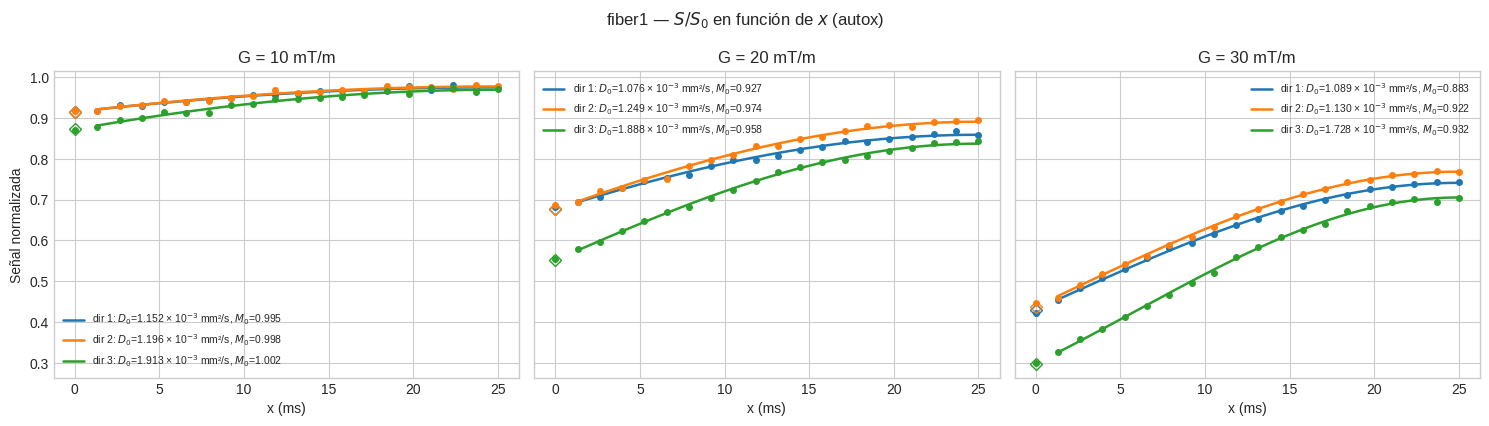

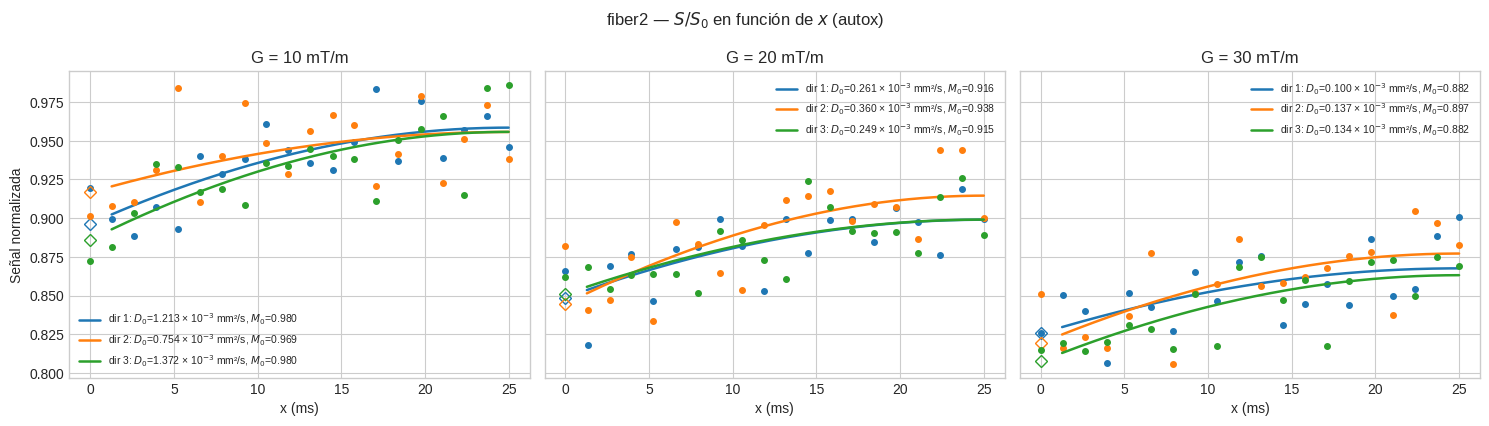

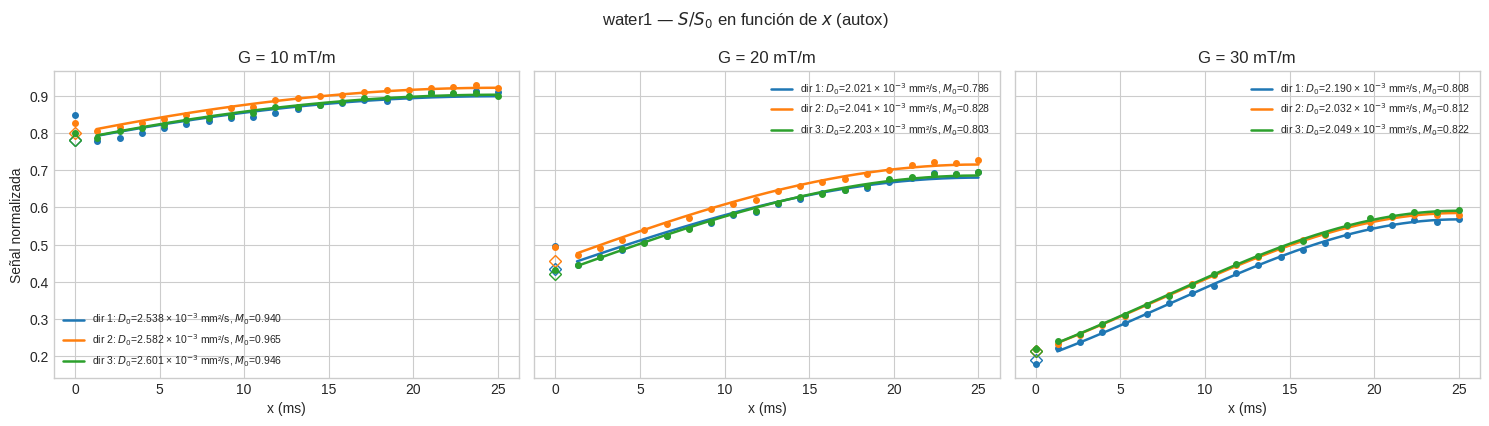

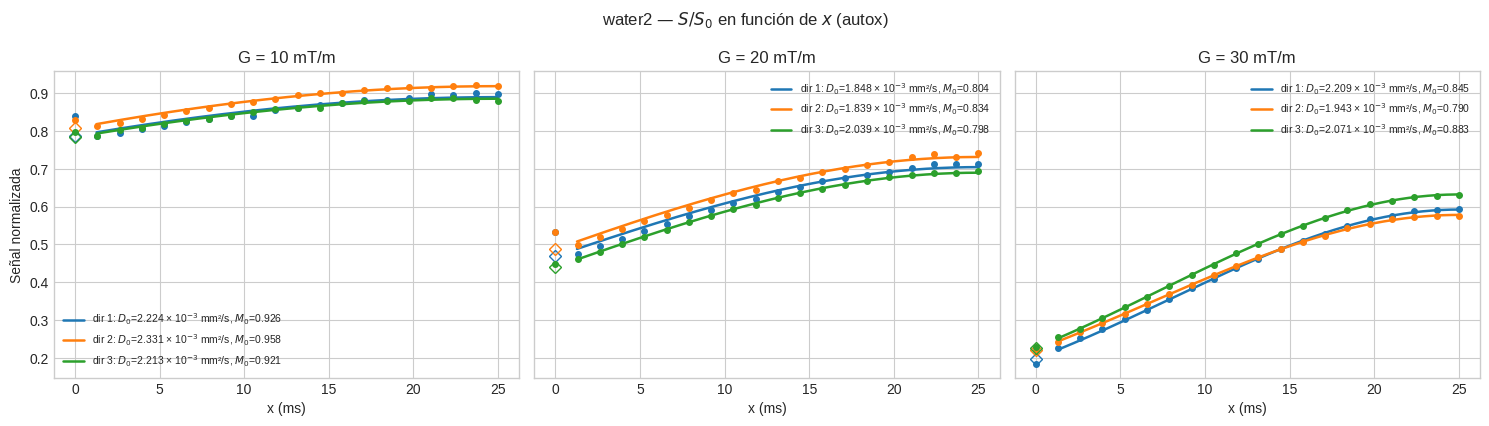

In [5]:
for roi in rois:
    fig, axes = panel_figure(len(g_values), f'{roi} — $S/S_0$ en función de $x$ ({OUTPUT_NAME})')
    for ax, g_value in zip(axes, g_values):
        for direction, curve in data.loc[data['roi'].eq(roi) & data['G'].eq(g_value)].groupby('direction', sort=True):
            curve = curve.sort_values('x')
            color = direction_colors.get(direction)
            ax.plot(curve['x'], curve['value_norm'], 'o', color=color, ms=4)
            plot_fit_curve(ax, curve, fitted(signal_fits, roi, g_value, direction), color, f'dir {direction}')
        ax.set(title=f'G = {g_value:g} mT/m', xlabel='x (ms)')
        ax.legend(fontsize=7.5)
    axes[0].set_ylabel('Señal normalizada')
    fig.tight_layout()
    save_figure(fig, SIGNAL_DIR, f'signal_{roi}_by-direction')
    plt.show()

### Una figura por ROI: un panel por dirección con los tres $G$

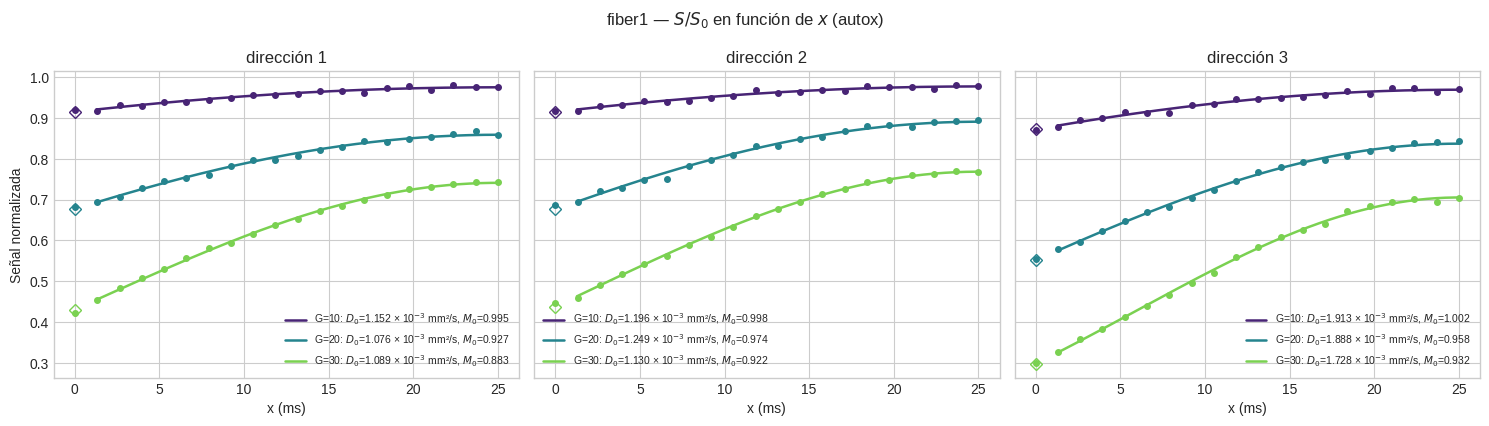

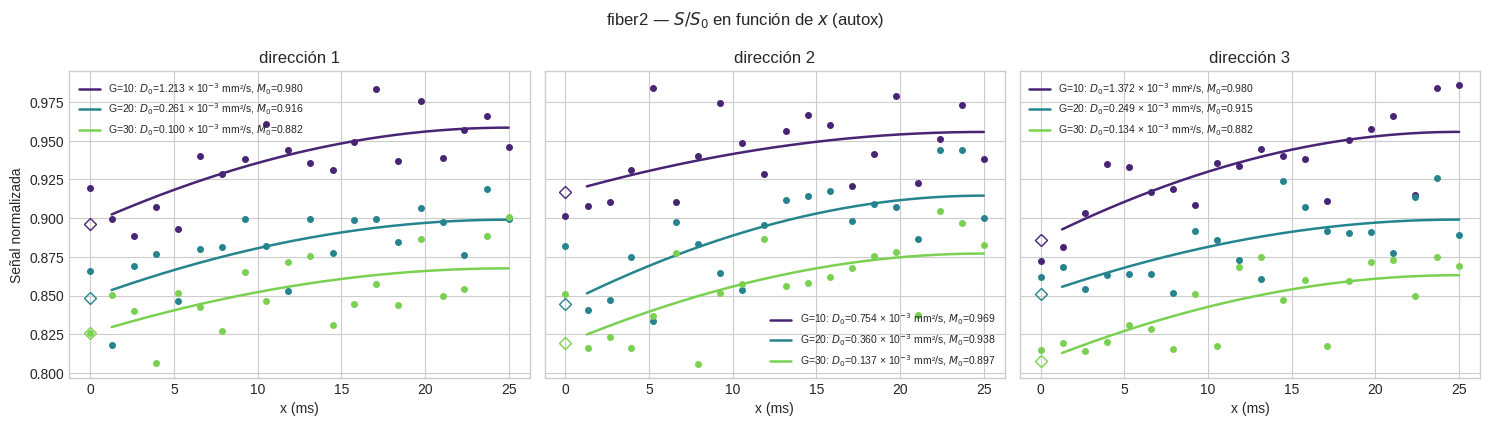

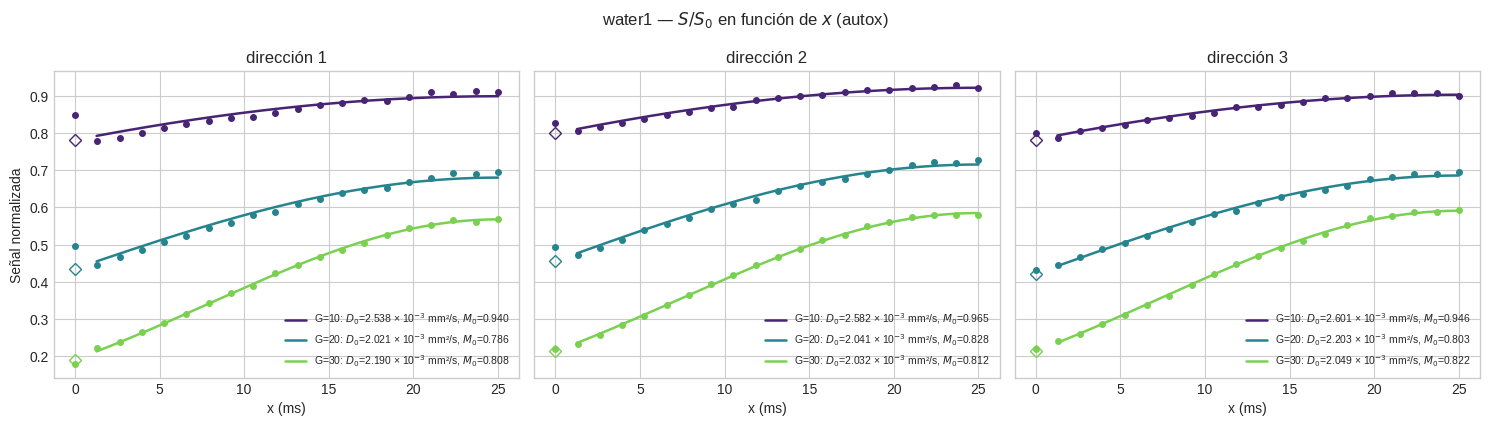

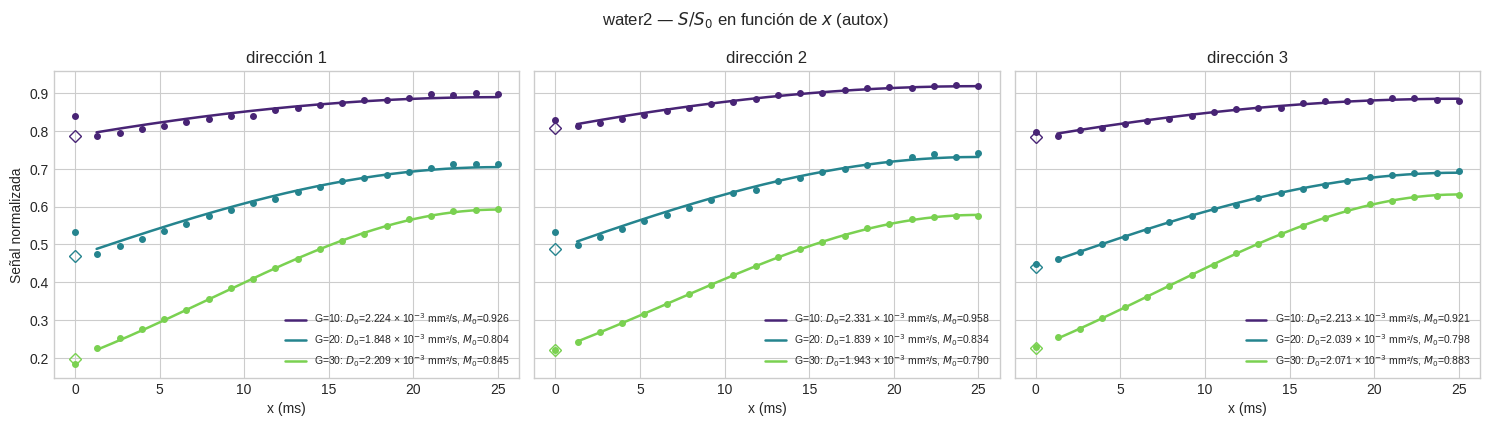

In [6]:
directions = sorted(data['direction'].unique())
for roi in rois:
    fig, axes = panel_figure(len(directions), f'{roi} — $S/S_0$ en función de $x$ ({OUTPUT_NAME})')
    for ax, direction in zip(axes, directions):
        for g_value, curve in data.loc[data['roi'].eq(roi) & data['direction'].eq(direction)].groupby('G', sort=True):
            curve = curve.sort_values('x')
            color = g_colors[g_value]
            ax.plot(curve['x'], curve['value_norm'], 'o', color=color, ms=4)
            plot_fit_curve(ax, curve, fitted(signal_fits, roi, g_value, direction), color, f'G={g_value:g}')
        ax.set(title=f'dirección {direction}', xlabel='x (ms)')
        ax.legend(fontsize=7.5)
    axes[0].set_ylabel('Señal normalizada')
    fig.tight_layout()
    save_figure(fig, SIGNAL_DIR, f'signal_{roi}_by-G')
    plt.show()

## Contraste respecto del límite Hahn, $\Delta M(x) = M(x) - M(0)$

Calculado punto a punto dentro de cada serie y ajustado con un $D_0$ por (ROI, $G$, dirección).

direction         1       2       3
roi    G                           
fiber1 10.0  1.0293  1.1187  1.9379
       20.0  1.0266  1.1511  1.8500
       30.0  1.1510  1.0615  1.7069
fiber2 10.0  0.6289  1.1381  1.7446
       20.0  0.1459  0.1135  0.1751
       30.0  0.1000  0.1000  0.1111
water1 10.0  0.6592  1.8104  2.0309
       20.0  1.1706  1.5265  2.0301
       30.0  2.3286  1.8994  1.9390
water2 10.0  0.7163  1.6935  1.8162
       20.0  1.0370  1.2617  1.9253
       30.0  2.3432  1.9364  2.0458

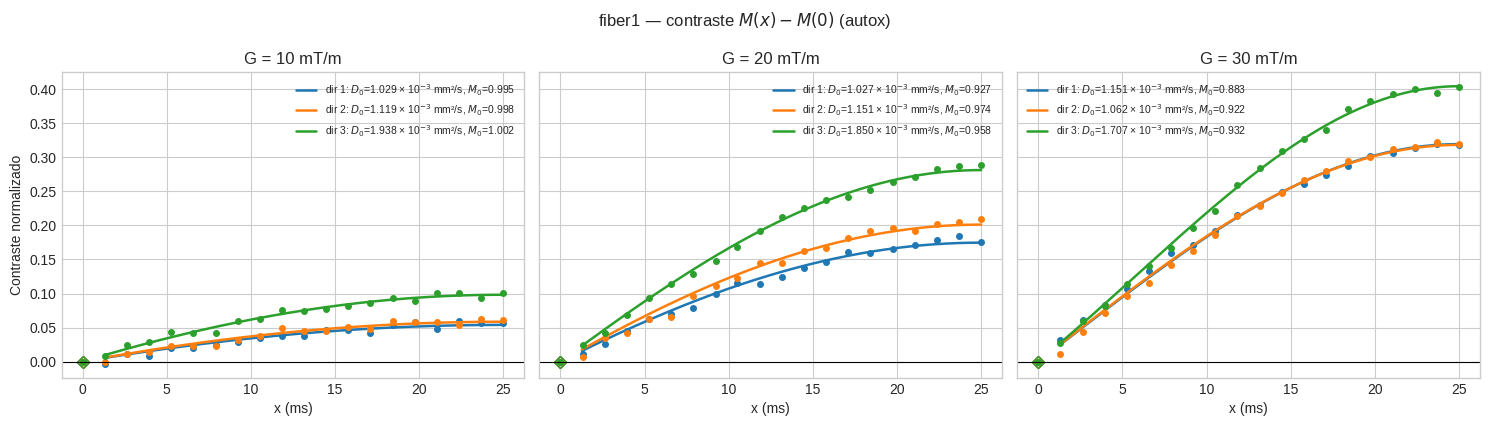

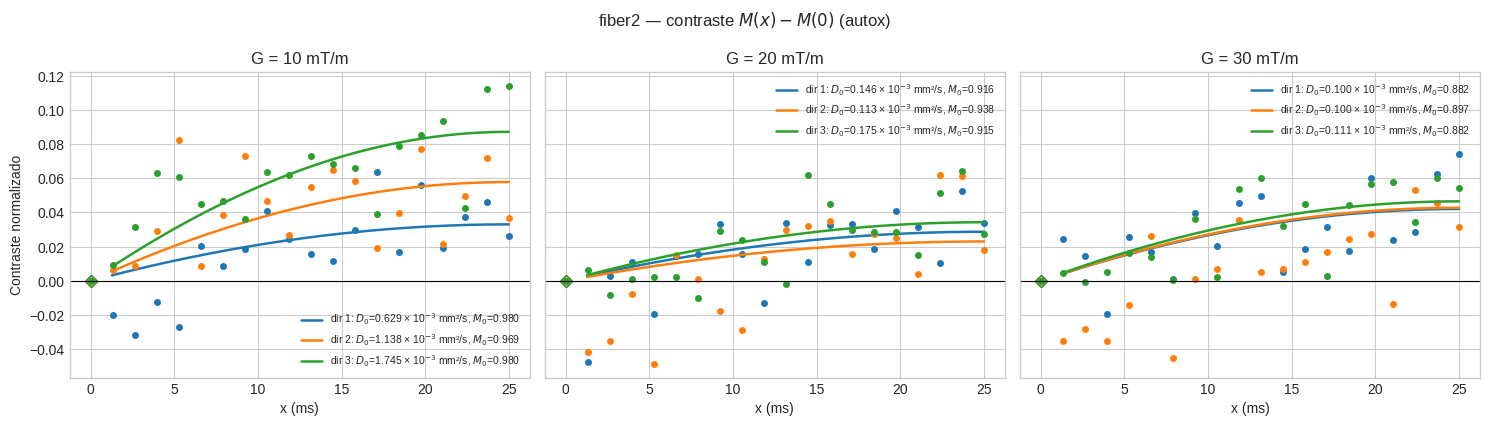

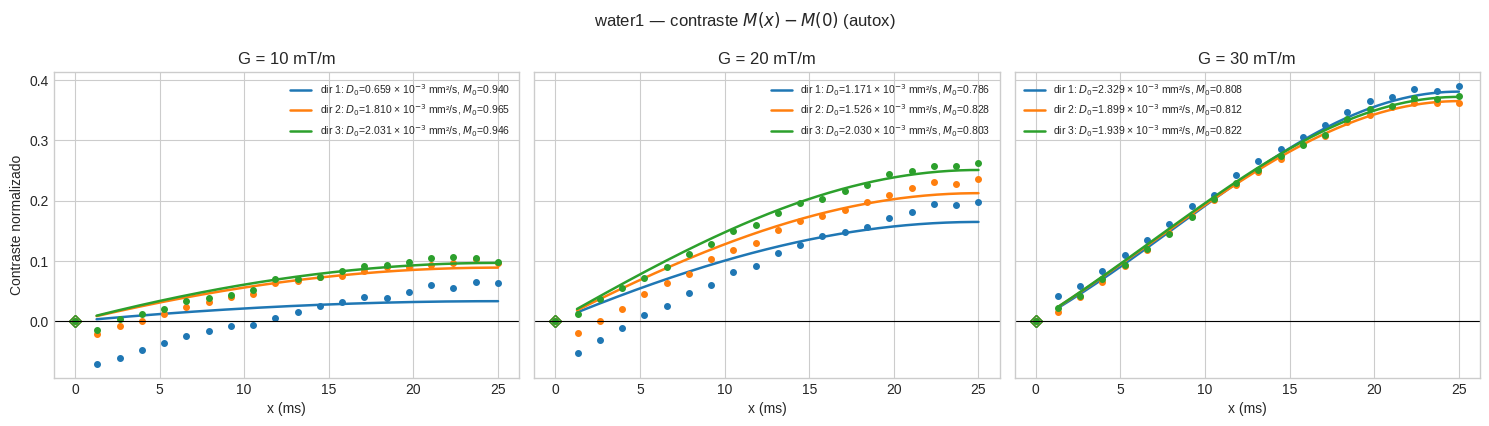

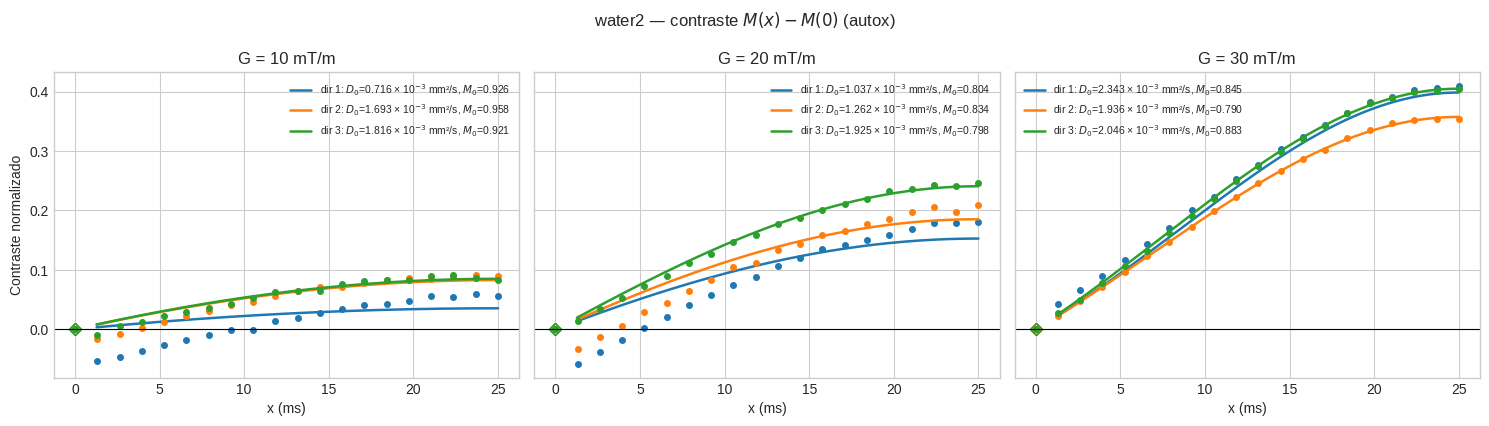

In [7]:
data['value_contrast'] = data['value_norm'] - data.groupby(['roi', 'G', 'direction'])['value_norm'].transform(
    lambda s: hahn_limit(data.loc[s.index], 'value_norm'))

contrast_fit_rows = []
for (roi, g_value, direction), curve in data.groupby(['roi', 'G', 'direction'], sort=True):
    curve = curve.sort_values('x')
    tn_ms, n_value, _g, ramp_ms = timing(curve)
    k = k_model(tn_ms, n_value, curve['x'], ramp_ms)
    k0 = k_model(tn_ms, n_value, 0.0, ramp_ms)
    m0 = fitted(signal_fits, roi, g_value, direction)['M0']  # M0 of the signal fit, D0 only
    fit = fit_one_parameter(curve['value_contrast'],
                            lambda d0: m0 * (np.exp(-k * g_value**2 * d0) - np.exp(-k0 * g_value**2 * d0)),
                            fit_m0=False)
    fit['M0'] = m0
    contrast_fit_rows.append({
        'model': 'trapezoidal_lobes', 'analysis_tag': ANALYSIS_TAG, 'subj': SUB, 'session_id': SESSION_ID,
        'roi': roi, 'G': g_value, 'direction': direction, 'TN': tn_ms, 'N': n_value,
        'contrast_at_x_max': float(curve['value_contrast'].iloc[-1]), **fit
    })

contrast_fits = pd.DataFrame(contrast_fit_rows).sort_values(['roi', 'G', 'direction'])
contrast_fits.to_csv(TABLE_DIR / 'contrast_fits.csv', index=False)
display(contrast_fits.pivot_table(index=['roi', 'G'], columns='direction', values='D0_mm2_s').mul(1e3).round(4))

for roi in rois:
    fig, axes = panel_figure(len(g_values), f'{roi} — contraste $M(x)-M(0)$ ({OUTPUT_NAME})')
    for ax, g_value in zip(axes, g_values):
        for direction, curve in data.loc[data['roi'].eq(roi) & data['G'].eq(g_value)].groupby('direction', sort=True):
            curve = curve.sort_values('x')
            color = direction_colors.get(direction)
            ax.plot(curve['x'], curve['value_contrast'], 'o', color=color, ms=4)
            plot_fit_curve(ax, curve, fitted(contrast_fits, roi, g_value, direction), color, f'dir {direction}',
                           model=contrast_model)
        ax.axhline(0, color='k', lw=0.8)
        ax.set(title=f'G = {g_value:g} mT/m', xlabel='x (ms)')
        ax.legend(fontsize=7.5)
    axes[0].set_ylabel('Contraste normalizado')
    fig.tight_layout()
    save_figure(fig, CONTRAST_DIR, f'contrast_{roi}')
    plt.show()

## Diagnóstico de las diferencias entre direcciones

Igual que en los notebooks en $G$: `max_direction_range` es la máxima separación entre las tres direcciones a un mismo $x$, `rms_direction_spread` la dispersión respecto de la media direccional y `D0_cv_percent` la variación de los $D_0$ ajustados entre direcciones.

In [8]:
qc_rows = []
for (roi, g_value), panel in data.groupby(['roi', 'G'], sort=True):
    wide = panel.pivot(index='b_step', columns='direction', values='value_norm')
    point_spread = wide.sub(wide.mean(axis=1), axis=0)
    d0 = signal_fits.loc[signal_fits['roi'].eq(roi) & signal_fits['G'].eq(g_value), 'D0_mm2_s']
    qc_rows.append({
        'subj': SUB, 'roi': roi, 'G': g_value,
        'max_direction_range': float((wide.max(axis=1) - wide.min(axis=1)).max()),
        'rms_direction_spread': float(np.sqrt(np.nanmean(point_spread.to_numpy()**2))),
        'D0_mean_mm2_s': float(d0.mean()),
        'D0_cv_percent': float(100 * d0.std(ddof=1) / d0.mean()),
    })

direction_qc = pd.DataFrame(qc_rows)
direction_qc.to_csv(TABLE_DIR / 'direction_qc.csv', index=False)
display(direction_qc)

,subj,roi,G,max_direction_range,rms_direction_spread,D0_mean_mm2_s,D0_cv_percent
0,PHANTOM-3,fiber1,10.0,0.048788,0.011002,0.001421,30.071477
1,PHANTOM-3,fiber1,20.0,0.131781,0.037737,0.001404,30.472097
2,PHANTOM-3,fiber1,30.0,0.146833,0.045607,0.001316,27.182257
3,PHANTOM-3,fiber2,10.0,0.090789,0.017199,0.001113,28.816949
4,PHANTOM-3,fiber2,20.0,0.067912,0.014142,0.000290,20.975621
5,PHANTOM-3,fiber2,30.0,0.054782,0.013398,0.000124,16.741159
6,PHANTOM-3,water1,10.0,0.047266,0.011080,0.002574,1.240227
7,PHANTOM-3,water1,20.0,0.065397,0.015800,0.002088,4.774394
8,PHANTOM-3,water1,30.0,0.038279,0.011139,0.002090,4.169037
9,PHANTOM-3,water2,10.0,0.043632,0.014363,0.002256,2.884902


## Resumen: $D_0$ en función de $G$ y todas las curvas en un eje $b$

Para difusión libre $D_0$ no depende de $G$ (`CV_over_G_%`) y, contra el $b$ exacto del `.bval`, los 60 puntos de cada ROI y dirección (3 $G$ × 20 $x$) caen sobre una sola exponencial $e^{-bD_0}$. Una restricción o el piso de ruido se ven como una separación de las series de distinto $G$.

G,10.0,20.0,30.0,CV_over_G_%
roi,,,,
fiber1,1.4206,1.4041,1.3157,4.0865
fiber2,1.1131,0.2900,0.1239,104.0802
water1,2.5738,2.0881,2.0903,12.4299
water2,2.2556,1.9086,2.0745,8.3470


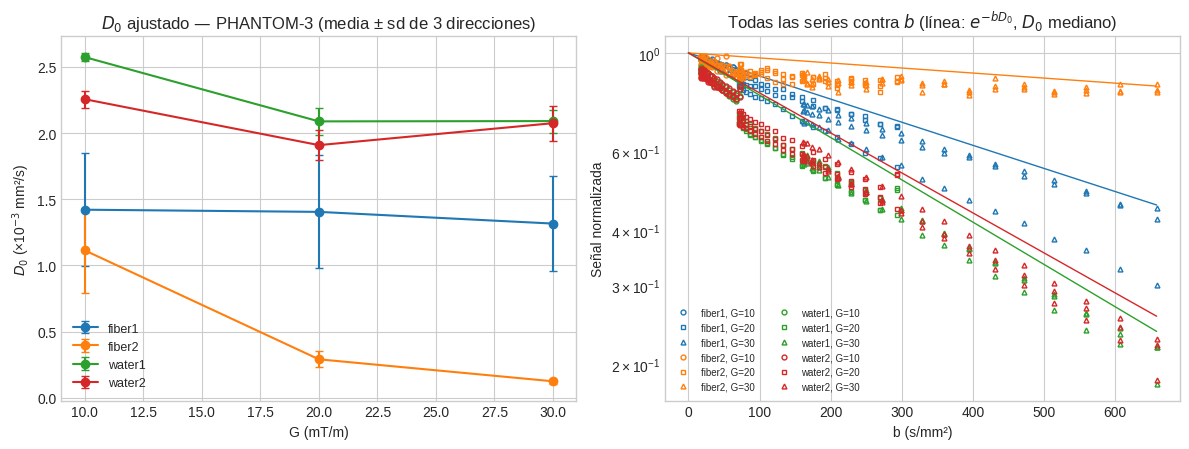

In [9]:
summary = signal_fits.groupby(['roi', 'G'])['D0_mm2_s'].agg(['mean', 'std']).mul(1e3)
d0_by_g = summary['mean'].unstack('G')
d0_by_g['CV_over_G_%'] = 100 * d0_by_g.std(axis=1, ddof=1) / d0_by_g.mean(axis=1)
d0_by_g.to_csv(TABLE_DIR / 'D0_summary_1e-3_mm2_s.csv')
display(d0_by_g.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.6))
for roi in rois:
    rows = summary.loc[roi]
    axes[0].errorbar(rows.index, rows['mean'], yerr=rows['std'], fmt='o-', capsize=3, label=roi)
axes[0].set(xlabel='G (mT/m)', ylabel='$D_0$ (×10$^{-3}$ mm²/s)',
            title=f'$D_0$ ajustado — {SUB} (media ± sd de 3 direcciones)')
axes[0].legend(fontsize=9)

b_fine = np.linspace(0, data['bvalue'].max(), 300)
for roi, color in zip(rois, plt.cm.tab10.colors):
    roi_data = data.loc[data['roi'].eq(roi)]
    for g_value, marker in zip(g_values, ['o', 's', '^', 'D']):
        points = roi_data.loc[roi_data['G'].eq(g_value)]
        axes[1].semilogy(points['bvalue'], points['value_norm'], marker, color=color, ms=3.5, mfc='none',
                         label=f'{roi}, G={g_value:g}')
    d0_roi = signal_fits.loc[signal_fits['roi'].eq(roi), 'D0_mm2_s'].median()
    axes[1].semilogy(b_fine, np.exp(-b_fine * d0_roi), '-', color=color, lw=1)
axes[1].set(xlabel='b (s/mm²)', ylabel='Señal normalizada', title='Todas las series contra $b$ (línea: $e^{-bD_0}$, $D_0$ mediano)')
axes[1].legend(fontsize=7, ncol=2)
fig.tight_layout()
save_figure(fig, SUMMARY_DIR, 'D0_vs_G_and_signal_vs_b')
plt.show()

## Comprobación: $k$ del modelo frente al `bvalue` de la tabla

`k_from_bvalue` = `bvalue`/$G^2$ de cada punto; el cociente con `k_model(x)` debe ser 1 (salvo $3\times10^{-5}$ por $\gamma$), porque el ingest calculó $x$ invirtiendo justamente esa relación.

In [10]:
k_rows = []
for (g_value, b_step), points in data.groupby(['G', 'b_step'], sort=True):
    tn_ms, n_value, _g, ramp_ms = timing(points)
    x_ms = float(points['x'].mean())
    k_table = float(np.median(points['bvalue'] / g_value**2))
    k_rows.append({'G': g_value, 'b_step': b_step, 'x_ms': x_ms, 'k_model': k_model(tn_ms, n_value, x_ms, ramp_ms)[0],
                   'k_from_bvalue': k_table})
k_check = pd.DataFrame(k_rows)
k_check['k_from_bvalue_over_k_model'] = k_check['k_from_bvalue'] / k_check['k_model']
k_check.to_csv(TABLE_DIR / 'k_check.csv', index=False)
display(k_check['k_from_bvalue_over_k_model'].describe().to_frame().T)

,count,mean,std,min,25%,50%,75%,max
k_from_bvalue_over_k_model,60.0,0.999931,2.612181e-09,0.999931,0.999931,0.999931,0.999931,0.999931


## Opcional: modelo restringido ($\tau_c$ con $D_0$ fijo)

`M_nogse_rest(T, G, N, x, tc, M0=1, D0)` de `models/model_fitting.py` (fase gaussiana con correlación exponencial, $l_c=\sqrt{D_0\tau_c}$), con $D_0$ fijo en el agua libre (`D0_FREE_MM2_S`) y $\tau_c$ libre, un ajuste por (ROI, $G$, dirección). Es el modelo de lóbulos **rectangulares**: con rampas de 0.32 ms la diferencia de contraste con el trapezoidal es de 2–8 % para restricciones de 3–5 µm. Útil para las fibras; en el agua da $\tau_c$ en el límite superior.

In [11]:
from models.model_fitting import M_nogse_rest

RUN_RESTRICTED = True
D0_FREE_MM2_S = float(signal_fits.loc[signal_fits['roi'].str.startswith('water'), 'D0_mm2_s'].median())
TC_BOUNDS_MS = (0.05, 500.0)
MM2_S_TO_M2_MS = 1e-9  # D0 of model_fitting in m^2/ms


def restricted_model(curve, x_ms, tc_ms):
    tn_ms, n_value, g_value, _ramp = timing(curve)
    return M_nogse_rest(tn_ms, g_value, n_value, np.atleast_1d(x_ms), tc_ms, 1.0, D0_FREE_MM2_S * MM2_S_TO_M2_MS)


if RUN_RESTRICTED:
    print(f'D0 libre usado: {D0_FREE_MM2_S * 1e3:.4f} × 1e-3 mm²/s (mediana de los ROIs de agua)')
    rest_rows = []
    for (roi, g_value, direction), curve in data.groupby(['roi', 'G', 'direction'], sort=True):
        curve = curve.sort_values('x')
        y = curve['value_norm'].to_numpy(float)
        lo, hi = np.log(TC_BOUNDS_MS)

        def loss(log_tc):
            prediction = restricted_model(curve, curve['x'], np.exp(log_tc))
            return np.mean((y - best_m0(y, prediction) * prediction)**2)

        result = minimize_scalar(loss, bounds=(lo, hi), method='bounded')
        tc = float(np.exp(result.x))
        rest_rows.append({'roi': roi, 'G': g_value, 'direction': direction, 'tc_ms': tc,
                          'M0': best_m0(y, restricted_model(curve, curve['x'], tc)),
                          'lc_um': float(np.sqrt(D0_FREE_MM2_S * 1e-6 * tc * 1e-3) * 1e6),
                          'rmse': float(np.sqrt(result.fun)), 'tc_at_bound': bool(np.isclose(tc, TC_BOUNDS_MS, rtol=1e-3).any())})
    restricted_fits = pd.DataFrame(rest_rows)
    restricted_fits.to_csv(TABLE_DIR / 'restricted_fits.csv', index=False)
    display(restricted_fits.pivot_table(index=['roi', 'G'], columns='direction', values='lc_um').round(2))
print('Figuras y tablas guardadas en:', OUTPUT_ROOT)

D0 libre usado: 2.1307 × 1e-3 mm²/s (mediana de los ROIs de agua)


direction        1      2      3
roi    G                        
fiber1 10.0   9.03   9.33  20.95
       20.0   8.56   9.70  19.87
       30.0   8.64   8.89  15.38
fiber2 10.0   9.45   6.86  10.69
       20.0   4.65   5.12   4.59
       30.0   3.67   3.95   3.93
water1 10.0  32.64  32.64  32.64
       20.0  28.43  30.79  32.64
       30.0  32.64  29.62  31.94
water2 10.0  32.64  32.64  32.64
       20.0  18.44  18.15  30.61
       30.0  32.64  22.46  32.64

Figuras y tablas guardadas en: /mnt/storage/tier2/MUMI-EXT-001/mumi-data/Project-NOGSE/repos/signal_analysis/results/autox/sub-PHANTOM-3/ses-20261026NOGSEV2003FOV220M128SL01R1AUTOX
